# Test of Discretization Algorithms

In [1]:
%matplotlib inline

import plotly.io as pio
from scipy.constants import c, pi

pio.renderers.default = (
    "notebook_connected"  # 'browser' for avoid error but shown in the browser
)

# import surpRISe
from surpRISe.channels.tx2ris2rx.tang_general_channel import tang_general_channel
from surpRISe.components.antenna import Antenna
from surpRISe.components.ris import RIS
from surpRISe.utils.utils import *

In [10]:
# Create Objects
f = 28e9
lam = c / f

ris = RIS(
    name="RIS",
    center=[0, 0, 0],
    boresight="z",
    Ncol=64,
    Nrow=64,
    delta_h=lam / 2,
    delta_v=lam / 2,
    dx=0.47 * lam,
    dy=0.47 * lam,
    fc=f,
    radiation_factor=1,
    phase_shifts_dict={"0": 0, "1": pi},
    att_dict={"0": 1, "1": 1},
)

tx_pos = sph2cart([2, 0, 0])
tx_antenna = Antenna(tx_pos, 0)

rx_pos = sph2cart([2, 180, 45])
rx_antenna = Antenna(rx_pos, 0)

ch = tang_general_channel()


--- Testing optimization algorithm: direct_disc
Optimizer 'discrete direct_disc': Optimizing time 0.0022 sec.
Final Normalized BF Gain with direct_disc: 0.4060

--- Testing optimization algorithm: chen_alg1
Optimizer 'discrete chen_alg1': Optimizing time 0.0035 sec.
Final Normalized BF Gain with chen_alg1: 0.4061

--- Testing optimization algorithm: grid_search
Optimum value of α: 0.770 rad
Optimizer 'discrete grid_search': Optimizing time 0.1436 sec.
Plotting Grid Search Landscape...


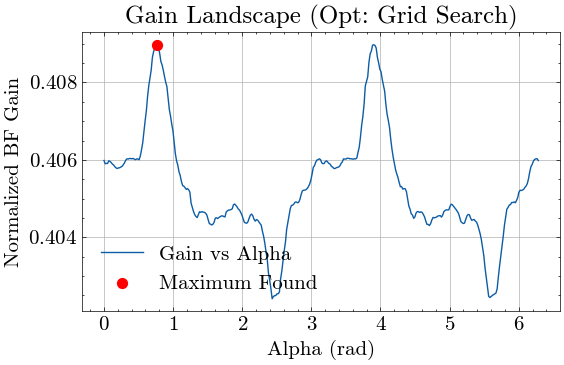

Final Normalized BF Gain with grid_search: 0.4090

--- Testing optimization algorithm: 1d_search
1D Search: Trying 4097 angles. Optimal alpha=0.770 rad
Optimizer 'discrete 1d_search': Optimizing time 1.5350 sec.
Plotting 1D Search Landscape...


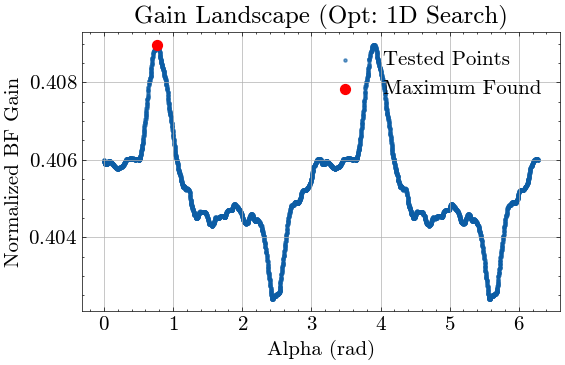

Final Normalized BF Gain with 1d_search: 0.4090

--- Testing optimization algorithm: iterative
Iterative solution converged in 5 iterations.
Optimum value of α found: -0.020 rad
Optimizer 'discrete iterative': Optimizing time 0.0032 sec.
Plotting Iterative Convergence...


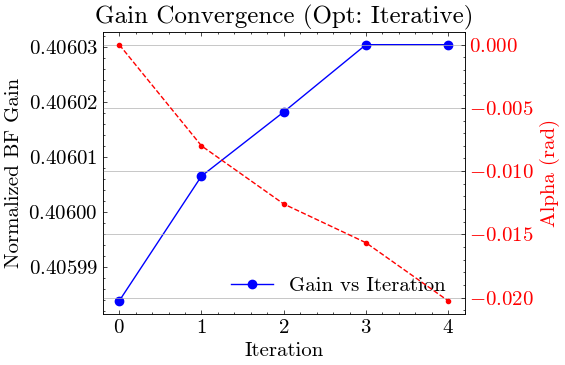

Final Normalized BF Gain with iterative: 0.4060

--- Summary of Beamforming Gains:
Algorithm: direct_disc     | BF Gain: 0.4060
Algorithm: chen_alg1       | BF Gain: 0.4061
Algorithm: grid_search     | BF Gain: 0.4090
Algorithm: 1d_search       | BF Gain: 0.4090
Algorithm: iterative       | BF Gain: 0.4060


In [11]:
# Test different algorithms
algorithms = ["direct_disc", "chen_alg1", "grid_search", "1d_search", "iterative"]
# algorithms = ['direct_disc', 'chen_alg1', 'grid_search', 'iterative']
verbose = True
bf_list = []

max_bf = (ris.Nrow * ris.Ncol) ** 2

for alg in algorithms:
    print(f"\n--- Testing optimization algorithm: {alg}")
    ris.reset_ris()
    ch.optimize(
        optimizer=alg,
        mode="disc",
        wave_model="spherical",
        tx_antenna=tx_antenna,
        rx_antenna=rx_antenna,
        ris=ris,
        verbose=verbose,
    )
    # ris.plot_phase_dist()
    bf = ch.phase_bf_multrx(tx_antenna=tx_antenna, rx_positions=rx_pos, ris=ris)
    bf_gain = bf[0] / max_bf
    print(f"Final Normalized BF Gain with {alg}: {bf_gain:.4f}")

    bf_list.append((alg, bf_gain))

# Summary of results
print("\n--- Summary of Beamforming Gains:")

res_str = "\n".join(
    f"Algorithm: {alg:15s} | BF Gain: {gain:.4f}" for alg, gain in bf_list
)
print(res_str)